# 04. Coverage optimisation: greedy and certified optimum

This notebook covers **phase 3**: choosing which configurations to install, under a budget, to maximise the
expected weighted coverage. The full formulation and the proofs are in `docs/formulation.md` (§1-6).

**Objective.** With $x_j \in \{0, 1\}$ for each configuration and independent detections, an intruder at cell
$i$ escapes detection only if they escape every installed sensor:

$$
\max_{x, y} \; F(x) = \sum_{i} w_i \left( 1 - \prod_{j} (1 - P_{ij})^{x_j} \right)
$$

**Constraints.** (C1) budget $\sum_j a_j x_j + \sum_s f_s y_s \le B$, a support (mast or roof mount) being paid
only once; (C2) a sensor needs its support, $x_j \le y_{s(j)}$; (C3) a single height per location;
(C4) at most 1 radar and 4 cameras per support.

In [8]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src.analysis, src.intruder_evaluation, src.nsga_analysis, src.pareto  # noqa: F401  (they select the Agg backend)
from src.site import load_config

%matplotlib inline

cfg = load_config()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
pd.set_option("display.width", 160)

## 1. Submodularity: diminishing returns

Write $q_i(T) = \prod_{j \in T} (1 - P_{ij})$ for the probability that cell $i$ is missed by the set $T$. The
marginal gain of adding $j$ is

$$
\Delta_j(T) = F(T \cup \{j\}) - F(T) = \sum_i w_i \, q_i(T) \, P_{ij}.
$$

Since $q_i(T)$ decreases when $T$ grows, $\Delta_j(T)$ decreases too: $F$ is **monotone and submodular**. A
practical consequence: every marginal gain is obtained at once by a sparse matrix-vector product,
$\Delta = A\,(w \odot q)$. A toy check:

In [9]:
from scipy import sparse

from src.instance import Instance, cost, evaluate, non_detection, violations


def make(P, w=None, support=None, kind=None, a=None, site=None, f=None, cap=(4, 1)):
    '''A small instance: P is (configurations × cells); by default one support per configuration.'''
    P = np.asarray(P, float)
    nJ, nI = P.shape
    support = np.arange(nJ) if support is None else np.asarray(support)
    nS = support.max() + 1
    return Instance(A=sparse.csr_matrix(P), w=np.ones(nI) if w is None else np.asarray(w, float),
                    support=support, kind=np.zeros(nJ, int) if kind is None else np.asarray(kind),
                    cost_sensor=np.ones(nJ) if a is None else np.asarray(a, float),
                    site=np.arange(nS) if site is None else np.asarray(site),
                    cost_support=np.zeros(nS) if f is None else np.asarray(f, float),
                    capacity=np.asarray(cap))


rng = np.random.default_rng(0)
toy = make(rng.uniform(0, 1, (6, 30)) * (rng.uniform(size=(6, 30)) < 0.5))
j = 5
rows = []
for T in ([], [0], [0, 1], [0, 1, 2], [0, 1, 2, 3], [0, 1, 2, 3, 4]):
    q = non_detection(toy, T)
    delta_formula = (toy.A[j] @ (toy.w * q)).item()
    delta_direct = evaluate(toy, T + [j]) - evaluate(toy, T)
    rows.append(dict(T=str(T), gain_of_5_formula=round(delta_formula, 4),
                     gain_of_5_direct=round(delta_direct, 4)))
pd.DataFrame(rows)

,T,gain_of_5_formula,gain_of_5_direct
0,[],8.3584,8.3584
1,[0],6.9581,6.9581
2,"[0, 1]",6.1306,6.1306
3,"[0, 1, 2]",3.5209,3.5209
4,"[0, 1, 2, 3]",3.2396,3.2396
5,"[0, 1, 2, 3, 4]",1.6668,1.6668


## 2. The ratio greedy, and why it has no guarantee here

At each step the greedy picks the admissible configuration with the best **gain / marginal cost** ratio,
where the marginal cost includes the support if it is not open yet. It returns the best of this greedy
solution and the best single sensor (the ratio alone can be arbitrarily bad, Khuller et al. 1999).

The classic $(1 - 1/e)$ guarantee holds for a cardinality constraint; with shared support costs and the
height lock-in (C3), no guarantee survives. Two constructed cases, compared with brute force:

In [10]:
from itertools import combinations

from src.greedy import greedy, ratio_greedy


def brute_force(inst, budget):
    best, best_T = 0.0, ()
    for k in range(1, inst.n_configs + 1):
        for T in combinations(range(inst.n_configs), k):
            if not violations(inst, T, budget) and evaluate(inst, T) > best:
                best, best_T = evaluate(inst, T), T
    return best, best_T


# Height lock-in: two heights of the same mast; 10 m sees 3 cells, 4 m only one but is much cheaper
lock = make(np.array([[1, 0, 0], [1, 1, 1]], float), support=[0, 1], site=[0, 0], a=[0.1, 3.0],
            f=[0.1, 0.1])
g = ratio_greedy(lock, 10.0)
print(f"height lock-in: ratio greedy picks {[int(j) for j in g.T]} (value {g.value:g}), "
      f"optimum {brute_force(lock, 10.0)}")

# Ratio alone: a cheap sensor with a tiny gain beats, in ratio, the one that covers everything
P = np.zeros((2, 101)); P[0, 0] = 1.0; P[1, 1:] = 1.0
trap = make(P, a=[0.01, 10.0])
print(f"ratio trap: ratio greedy {ratio_greedy(trap, 10.0).value:g}, "
      f"with the best singleton {greedy(trap, 10.0).value:g} (source: {greedy(trap, 10.0).source})")

height lock-in: ratio greedy picks [0] (value 1), optimum (3.0, (1,))
ratio trap: ratio greedy 1, with the best singleton 100 (source: singleton)


## 3. A certified optimum by submodular cuts

The compact linearisation of $F$ is correct but intractable on the site (3.3 M non-zeros, a relaxation
36 % above the best known solution). Instead, the cells are grouped into spatial blocks $g$ and the exact
problem is solved by **constraint generation** (Nemhauser and Wolsey, 1981). Each block function $F_g$ is
submodular, so for every sets $S$ and $T$:

$$
F_g(T) \le F_g(S) + \sum_{j \in T \setminus S} \rho_{gj}(S), \qquad \rho_{gj}(S) = \sum_{i \in g} w_i\, q_i(S)\, P_{ij}.
$$

The **master** MILP maximises $\sum_g \eta_g$ under (C1)-(C4) and the cuts $\eta_g \le F_g(S_k) + \sum_j
\rho_{gj}(S_k) x_j$ for every set $S_k$ visited so far. Its dual bound is an **upper bound** of the optimum;
each solution $T_k$, evaluated exactly, is a **lower bound**. The cut at $T_k$ is added and the master is
solved again until the gap closes. On a random toy instance with 12 configurations:

greedy 29.342 | certified optimum 35.550 (UB 35.550, 4 iterations) | brute force 35.550, set (4, 5, 10, 11)


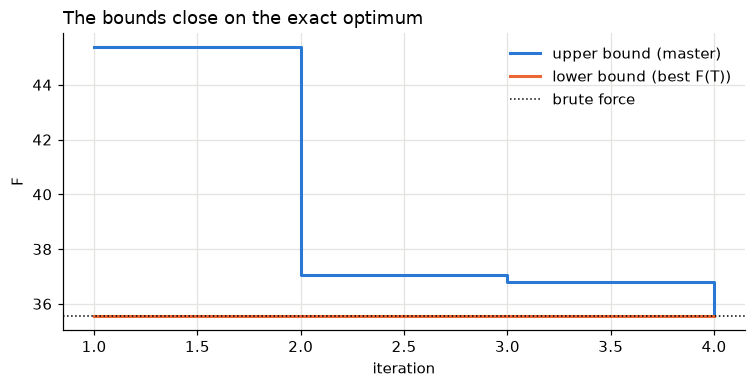

In [11]:
from src.milp import solve

nJ, B = 12, 6.0
groups = np.arange(60) % 6                        # 6 "spatial" blocks of cells
for seed in range(100):                           # a random instance where the greedy is not optimal
    rng = np.random.default_rng(seed)
    P = rng.uniform(0, 1, (nJ, 60)) * (rng.uniform(size=(nJ, 60)) < 0.3)
    toy = make(P, w=rng.uniform(0.5, 2, 60), support=np.repeat(np.arange(6), 2),
               kind=rng.integers(0, 2, nJ), a=rng.uniform(0.5, 3, nJ), site=np.repeat(np.arange(3), 2),
               f=rng.uniform(0.5, 2, 6))
    if greedy(toy, B).value < brute_force(toy, B)[0] - 1e-6:
        break
res = solve(toy, B, groups, gap_tol=0.0)
opt, T_opt = brute_force(toy, B)
print(f"greedy {greedy(toy, B).value:.3f} | certified optimum {res.value:.3f} (UB {res.ub:.3f}, "
      f"{res.iterations} iterations) | brute force {opt:.3f}, set {T_opt}")
h = res.history
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.step(h.iteration, h.ub, where="post", color="#2a78d6", lw=2, label="upper bound (master)")
ax.step(h.iteration, h.lb, where="post", color="#eb6834", lw=2, label="lower bound (best F(T))")
ax.axhline(opt, color="k", ls=":", lw=1, label="brute force")
ax.set_xlabel("iteration"); ax.set_ylabel("F"); ax.legend(frameon=False)
ax.set_title("The bounds close on the exact optimum", loc="left")
plt.show()

## 4. On the site

The instance of the site gathers the coverage matrix of notebook 03 and the costs. The greedy runs in
milliseconds for every budget; here is how it builds its solution at a budget of 8 units:

In [12]:
from src.greedy import describe
from src.instance import load_instance

inst, configs = load_instance(cfg, ROOT)
print(f"{inst.n_configs:,} configurations, {inst.n_supports} supports, {inst.A.shape[1]:,} cells")
sol = greedy(inst, 8.0)
tr = sol.trace.merge(configs[["cand", "h", "sensor", "azimuth"]], left_on="config", right_index=True)
tr["coverage_%"] = 100 * tr["F"] / inst.W
tr[["step", "cand", "h", "sensor", "azimuth", "opens_support", "marginal_cost", "gain", "spent",
    "coverage_%"]].round(2)

2,290 configurations, 112 supports, 3,774 cells


,step,cand,h,sensor,azimuth,opens_support,marginal_cost,gain,spent,coverage_%
0,1,C026,4.0,cam_wide,270.0,True,2.2,2717.25,2.2,17.96
1,2,C026,4.0,cam_wide,315.0,False,1.0,779.17,3.2,23.11
2,3,C035,4.0,cam_wide,135.0,True,2.2,1632.60,5.4,33.90
3,4,C033,4.0,cam_wide,180.0,True,2.2,812.37,7.6,39.27


The certified sweep over the budgets is run by `python -m src.milp` (reduced profile for a secondary site:
the optimum is bracketed within 120 s per budget rather than certified to 0.5 %). The coverage / budget
front, with the greedy and the certified band $[\text{LB}, \text{UB}]$:

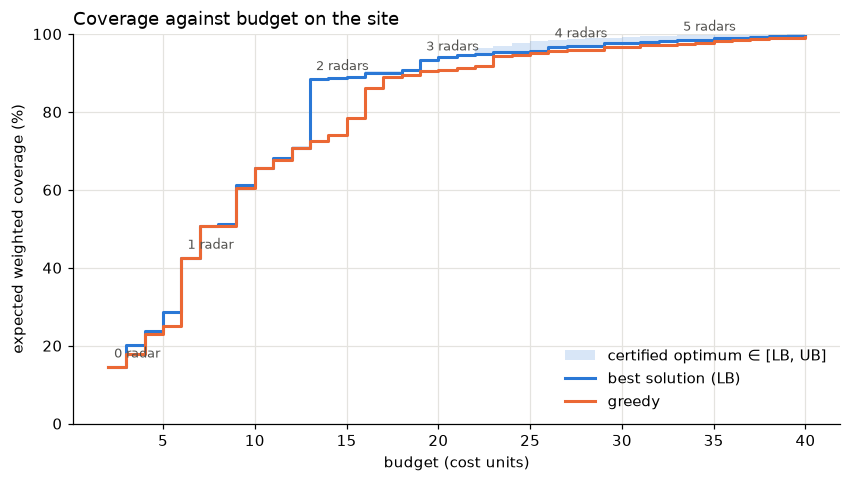

median greedy loss 1.0 %, worst 17.9 % at B = 13; widest certified gap 2.5 %


,budget,greedy,lb,ub,certified_gap,greedy_loss,n_radar,n_camera,heights
0,2.0,0.146,0.146,0.146,0.000,0.000,0,1,2
3,5.0,0.251,0.287,0.287,0.000,0.126,0,2,4 4
6,8.0,0.507,0.512,0.512,-0.000,0.008,1,1,6
9,11.0,0.677,0.682,0.685,0.004,0.007,1,2,4 4 4
12,14.0,0.740,0.887,0.889,0.002,0.166,2,0,6 6
15,17.0,0.890,0.901,0.906,0.005,0.013,2,2,4 6 6
18,20.0,0.908,0.941,0.944,0.004,0.035,3,0,4 6 8
21,23.0,0.944,0.953,0.969,0.016,0.010,3,2,4 4 6 6
24,26.0,0.956,0.968,0.984,0.016,0.012,4,0,2 4 6 10
27,29.0,0.966,0.977,0.991,0.014,0.011,4,1,2 4 8 8 10


In [13]:
from src.pareto import front_table

opt_dir = Path(cfg["optimization"]["out_dir"])
milp = pd.read_csv(opt_dir / "milp.csv")
f = front_table(milp, cfg["optimization"]["milp"]["target_gap"])
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.fill_between(f.budget, 100 * f.lb, 100 * f.ub, step="post", color="#2a78d6", alpha=0.18, lw=0,
                label="certified optimum ∈ [LB, UB]")
ax.step(f.budget, 100 * f.lb, where="post", color="#2a78d6", lw=2, label="best solution (LB)")
ax.step(f.budget, 100 * f.greedy, where="post", color="#eb6834", lw=2, label="greedy")
for _, r in f.drop_duplicates("n_radar").iterrows():
    ax.annotate(f"{int(r.n_radar)} radar{'s' if r.n_radar > 1 else ''}", (r.budget, 100 * r.lb),
                xytext=(4, 6), textcoords="offset points", fontsize=8.5, color="#52514e")
ax.set_xlabel("budget (cost units)"); ax.set_ylabel("expected weighted coverage (%)")
ax.set_ylim(0, 100); ax.legend(frameon=False, loc="lower right")
ax.set_title("Coverage against budget on the site", loc="left")
plt.show()
worst = f.loc[f.greedy_loss.idxmax()]
print(f"median greedy loss {100 * f.greedy_loss.median():.1f} %, worst {100 * worst.greedy_loss:.1f} % "
      f"at B = {worst.budget:g}; widest certified gap {100 * f.certified_gap.max():.1f} %")
f[["budget", "greedy", "lb", "ub", "certified_gap", "greedy_loss", "n_radar", "n_camera", "heights"]] \
    .iloc[::3].round(3)

With radars, the front rises by **radar steps** (not with `sensors.cameras_only`). The greedy is close to the optimum at most
budgets, but not everywhere: only the certified bracket reveals where it falls short (below), for example
when a second radar pays off only if the first one is placed differently.

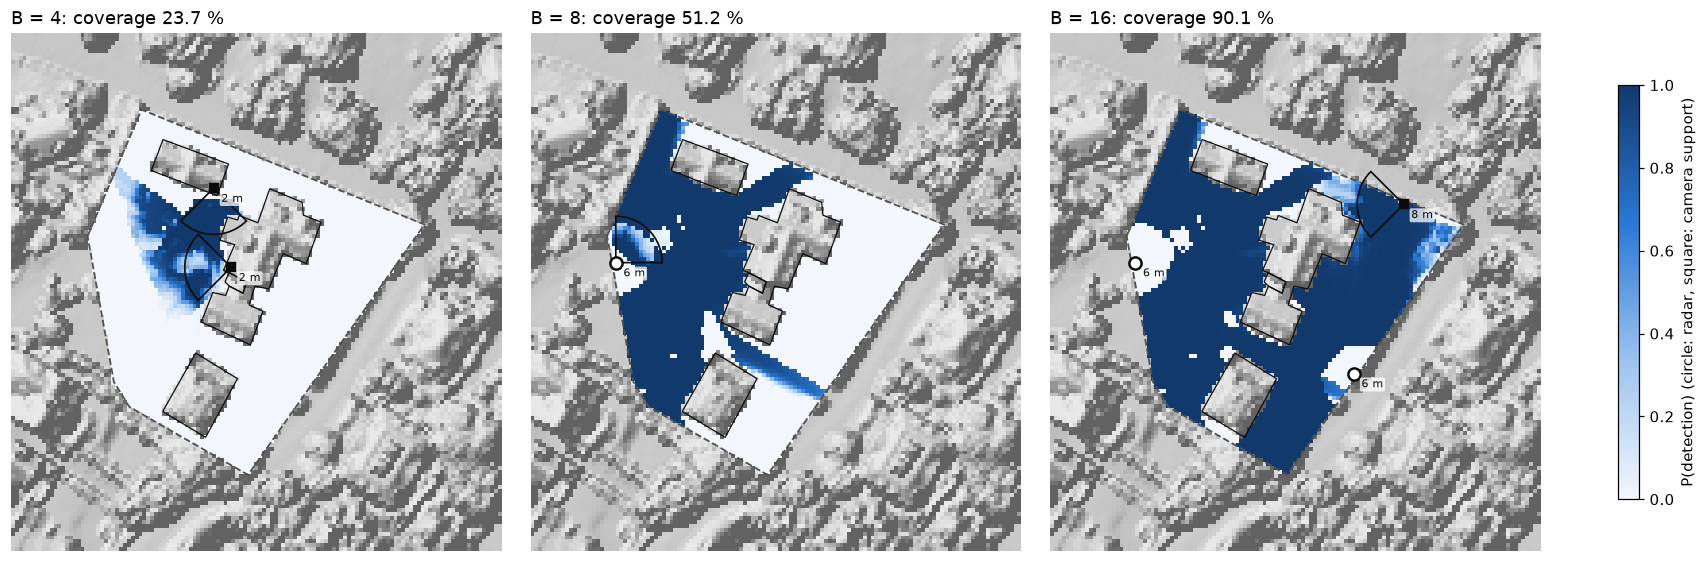

In [14]:
import geopandas as gpd

from src.analysis import SEQ, base_map, draw_sensors, hillshade, solutions, to_grid
from src.viewshed import read

cells = np.load(Path(cfg["coverage"]["out_dir"]) / "cells.npz")
rows, cols = cells["rows"], cells["cols"]
cand = gpd.read_file(cfg["candidates"]["output"]).set_index("id")
cand["x"], cand["y"] = cand.geometry.x, cand.geometry.y
layers = {"assets": gpd.read_file(cfg["site"]["output_gpkg"], layer="assets"),
          "perimeter": gpd.read_file(cfg["site"]["gpkg"], layer="perimeter")}
hfov = {c["name"]: c["hfov_deg"] for c in cfg["sensors"]["cameras"]}
sol_m = solutions(opt_dir / "milp_solutions.csv")
with __import__("rasterio").open(Path(cfg["rasters"]["out_dir"]) / "dsm.tif") as src_:
    dsm, tr_ = src_.read(1).astype(float), src_.transform
m = 20
r0, r1, c0, c1 = rows.min() - m, rows.max() + m + 1, cols.min() - m, cols.max() + m + 1
hs = hillshade(np.nan_to_num(dsm[r0:r1, c0:c1], nan=np.nanmedian(dsm)))
extent = (tr_.c + c0 * tr_.a, tr_.c + c1 * tr_.a, tr_.f + r1 * tr_.e, tr_.f + r0 * tr_.e)

budgets = [b for b in (4.0, 8.0, 16.0) if b in sol_m]
fig, axes = plt.subplots(1, len(budgets), figsize=(5.2 * len(budgets), 5), layout="constrained")
for ax, B in zip(np.atleast_1d(axes), budgets):
    det = 1 - non_detection(inst, sol_m[B])
    base_map(ax, hs, extent, layers)
    im = ax.imshow(to_grid(det, rows, cols, dsm.shape)[r0:r1, c0:c1], extent=extent, cmap=SEQ, vmin=0,
                   vmax=1, zorder=2, interpolation="nearest")
    draw_sensors(ax, sol_m[B], configs, cand, hfov, r_wedge=12)
    ax.set_xlim(extent[:2]); ax.set_ylim(extent[2:])
    ax.set_title(f"B = {B:g}: coverage {100 * evaluate(inst, sol_m[B]) / inst.W:.1f} %", loc="left")
fig.colorbar(im, ax=axes, shrink=0.8, label="P(detection) (circle: radar, square: camera support)")
plt.show()

Where the optimal sensors are, and what they see: cameras at small budgets, then radars, with cameras
filling the shadows the radars leave behind the buildings.

**Covering is not the end of the story.** These solutions maximise an *average*. An intruder who knows the
layout does not walk at random: [05. The intruder](05_intruder.ipynb) looks for the least watched path
through each of them.